# Amazon SageMaker Studio – Environment Exploration Demo

**Purpose:** Get familiar with the JupyterLab workspace in SageMaker Studio while completing a small Iris classification workflow.

**What you will explore:** Python environment, working directory, files, notebook cells, plots, model training, inference, and saved artifacts.

> This notebook runs the scikit-learn model directly in the JupyterLab space. It does not create a SageMaker managed training job or hosted endpoint.

**Run:** Execute the cells from top to bottom. Save the notebook with `Ctrl+S`.

## 1. Inspect the notebook environment
This first cell helps you understand which Python interpreter and working directory are active.

In [1]:
import os
import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Current working directory:", Path.cwd())
print("Files in current directory:")
for item in sorted(Path.cwd().iterdir()):
    print(" -", item.name)


Python version: 3.13.5
Python executable: /opt/pyvenv/bin/python
Current working directory: /mnt/data/sagemaker_studio_exploration
Files in current directory:
 - README.txt
 - SageMaker_Studio_Environment_Exploration.ipynb
 - Studio_Environment_Exploration_Guide.md


## 2. Import the libraries
The SageMaker Distribution image usually includes common ML libraries such as NumPy, pandas, Matplotlib, and scikit-learn. This cell confirms that the packages are available in the selected kernel.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import joblib

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)


NumPy: 2.3.5
pandas: 2.2.3
scikit-learn: 1.8.0
joblib: 1.5.3


## 3. Load a built-in dataset
We use the Iris dataset included with scikit-learn. It contains four flower measurements and three species labels. There is no external file to download.

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Make the target easier to read in the data preview.
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

display(df.head())
print("Dataset shape:", df.shape)
print("\nSpecies counts:")
print(df["species"].value_counts())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Dataset shape: (150, 6)

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 4. Explore the data with a simple chart
A scatter plot helps us visually inspect whether flower measurements separate the species.

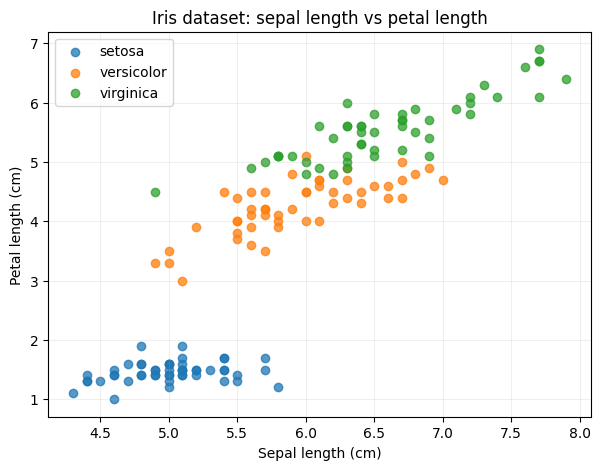

In [4]:
plt.figure(figsize=(7, 5))
for species in iris.target_names:
    subset = df[df["species"] == species]
    plt.scatter(
        subset["sepal length (cm)"],
        subset["petal length (cm)"],
        label=species,
        alpha=0.75
    )
plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal length (cm)")
plt.title("Iris dataset: sepal length vs petal length")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 5. Split the data into training and test sets
The model learns from the training set. We keep the test set aside to estimate performance on data it did not train on.

In [5]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 112
Test rows: 38


## 6. Train a classification model
We use a scikit-learn Pipeline so feature scaling is fitted only on the training data and then applied consistently to test and future data.

In [6]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


## 7. Evaluate the model
Accuracy is the fraction of correct predictions. The classification report shows precision, recall, and F1-score for each species. The confusion matrix shows the actual versus predicted classes.

Test accuracy: 0.921

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



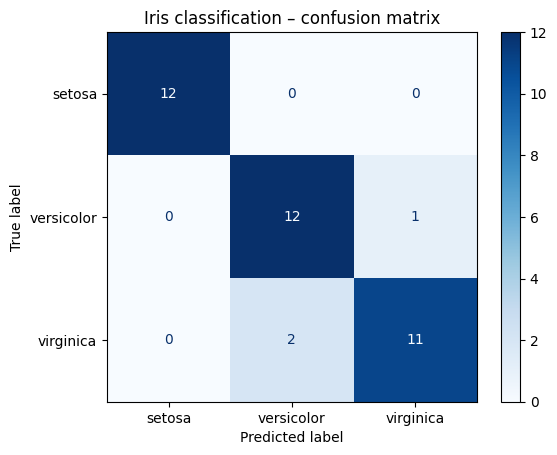

In [7]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Iris classification – confusion matrix")
plt.show()


## 8. Predict the species for a new flower
Change the measurements and rerun this cell to experiment with predictions. The feature order must match the four input columns shown below.

In [8]:
new_flower = pd.DataFrame([{
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}])

predicted_class = int(model.predict(new_flower)[0])
predicted_species = iris.target_names[predicted_class]
probabilities = model.predict_proba(new_flower)[0]

print("Input measurements:")
display(new_flower)
print("Predicted species:", predicted_species)
print("Class probabilities:")
for label, probability in zip(iris.target_names, probabilities):
    print(f"  {label}: {probability:.3f}")


Input measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted species: setosa
Class probabilities:
  setosa: 0.981
  versicolor: 0.019
  virginica: 0.000


## 9. Save the model and a run summary
This creates an `outputs` folder in the notebook's working directory. You can see it in the JupyterLab file browser and download the files from there.

In [9]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

model_path = output_dir / "iris_logistic_regression.joblib"
summary_path = output_dir / "run_summary.json"

joblib.dump(model, model_path)
summary = {
    "model": "StandardScaler + LogisticRegression",
    "dataset": "scikit-learn Iris",
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_accuracy": float(accuracy),
    "target_classes": iris.target_names.tolist()
}
summary_path.write_text(json.dumps(summary, indent=2))

print("Saved model:", model_path.resolve())
print("Saved summary:", summary_path.resolve())


Saved model: /mnt/data/sagemaker_studio_exploration/outputs/iris_logistic_regression.joblib
Saved summary: /mnt/data/sagemaker_studio_exploration/outputs/run_summary.json


## 10. Reload the saved model and run inference
The saved pipeline includes both scaling and the classifier, so the same preprocessing is applied after reloading.

In [10]:
loaded_model = joblib.load(model_path)
reloaded_prediction = int(loaded_model.predict(new_flower)[0])
print("Prediction from reloaded model:", iris.target_names[reloaded_prediction])
print("Model file size (bytes):", model_path.stat().st_size)


Prediction from reloaded model: setosa
Model file size (bytes): 1889


## 11. Explore the generated files in JupyterLab

In the JupyterLab file browser (left panel):

1. Refresh the file list if needed.
2. Open the `outputs` folder.
3. Select `run_summary.json` to inspect the recorded metrics.
4. Download `iris_logistic_regression.joblib` if you want to retain the trained model artifact.
5. Save this notebook with `Ctrl+S`.

### What to remember

- The notebook kernel runs Python code in the JupyterLab environment.
- The file browser shows files in the space's storage.
- The trained model is currently a local notebook artifact; it is not automatically registered in SageMaker Model Registry.
- This notebook does not create a SageMaker training job or endpoint.
- Stop the JupyterLab space when the demo is complete to stop compute charges. Storage charges may continue while the space exists.